# Public climate and hydrology sources with crc-sdk

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/public_data_sources.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/public_data_sources.ipynb)

A short tour of eight public sources. Each one is a crc-sdk provider read by the
same pipeline, [`pipelines/source_pipeline.py`](../../pipelines/source_pipeline.py):
`run(source, output)` selects a station, a box or a year window, writes the
provider's canonical rows atomically and records every downloaded resource's
URL, SHA-256, licence, attribution and retrieval time in `summary.json`.

Rows are in long format: one row per variable, place and time
(`variable_id`, `support_id`, `time`, `value`). A missing source value keeps its
row with a null `value` and a `failure` reason. None of these outputs is an asset
hazard estimate on its own.

| Source | What it is | Selection here |
|---|---|---|
| ECCC daily climate | Station observations (temperature, precipitation, snow, gusts) | Toronto Pearson `6158731`, 2020 |
| HYDAT | Daily mean river discharge and water level | Don River `02HA014`, 2020 |
| USGS | Daily mean discharge, source unit ft³/s | Gauges in a small box around `USGS-01491000`, 2020–2021 |
| CHIRPS v3 | Monthly precipitation on 0.05° pixels | A Nairobi box, 2020 |
| IBTrACS | Storm track points (USA agency wind and pressure) | Gulf of Mexico box, 2024 |
| NOAA extreme water levels | Detrended annual high water and published exceedance levels | Sewells Point `8638610` |
| NOAA 2022 sea-level scenarios | Relative sea-level change by scenario | Sewells Point `8638610` |
| NEX-GDDP-CMIP6 | Downscaled annual maximum daily precipitation | Toronto box, ACCESS-CM2 historical 2014 |

From a terminal the same reads are, for example,
`uv run python pipelines/source_pipeline.py --source hydat --station 02HA014`.
Run this notebook from a crc-docs checkout (`uv sync`, then `uv run jupyter lab`);
the first run needs internet access and later runs reuse the cache.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "crc-sdk[raster,netcdf]>=1,<2", "plotly>=6"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))
os.chdir(root)  # pipeline outputs go to pipeline_output/ in the checkout

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow.parquet as pq
import shapely

from crc_sdk import Projections
from pipelines.source_pipeline import Options, run

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
CACHE = Path("pipeline_output/source-cache")  # one verified cache for every source


def read(source, name="observations", **options):
    """Run one source through the pipeline and load its canonical rows."""
    summary = run(source, Path("pipeline_output") / source, options=Options(**options), cache=CACHE)
    table = pq.read_table(summary["outputs"][name]).to_pandas()
    artifact = summary["artifacts"][name]
    terms = {r["license"] for r in artifact["resources"] if r["license"]}
    print(f"{source}: {len(table):,} rows, {artifact['counts']['no_data']:,} without a value; "
          f"{len(artifact['resources'])} checksummed resources; terms: {', '.join(sorted(terms))}")
    return summary, table

## ECCC daily climate observations

Daily values as published by Environment and Climate Change Canada through
GeoMet. Each variable is its own row; a day the station did not report keeps a
null value rather than disappearing.

eccc-daily: 2,928 rows, 344 without a value; 2 checksummed resources; terms: OGL-Canada-2.0


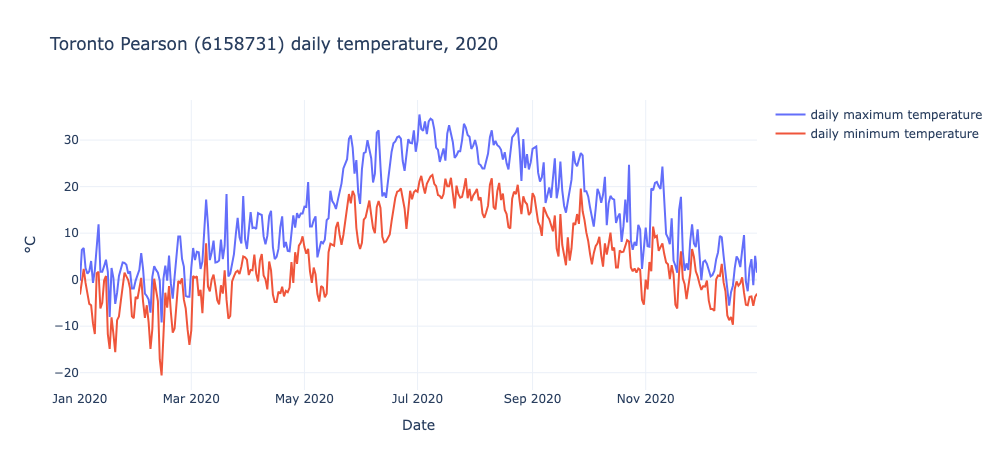

,with value,days
variable_id,,
eccc:daily_maximum_temperature,366,366
eccc:daily_maximum_wind_gust,311,366
eccc:daily_mean_temperature,366,366
eccc:daily_minimum_temperature,366,366
eccc:daily_total_precipitation,366,366
eccc:daily_total_rainfall,359,366
eccc:daily_total_snowfall,359,366
eccc:snow_depth,91,366


In [2]:
_, eccc = read("eccc-daily")
temperature = eccc[eccc.variable_id.isin(["eccc:daily_maximum_temperature", "eccc:daily_minimum_temperature"])]
fig = go.Figure([
    go.Scatter(x=group.time, y=group.value, mode="lines", name=name.split(":")[1].replace("_", " "))
    for name, group in temperature.groupby("variable_id")
])
fig.update_layout(title="Toronto Pearson (6158731) daily temperature, 2020",
                  xaxis_title="Date", yaxis_title="°C")
fig.show()
eccc.groupby("variable_id").value.agg(["count", "size"]).rename(columns={"count": "with value", "size": "days"})

## HYDAT daily discharge and water level

Historical Canadian gauge records via GeoMet. Discharge is flow through the gauge
section, not flood depth at a property.

hydat: 732 rows, 36 without a value; 2 checksummed resources; terms: OGL-Canada-2.0


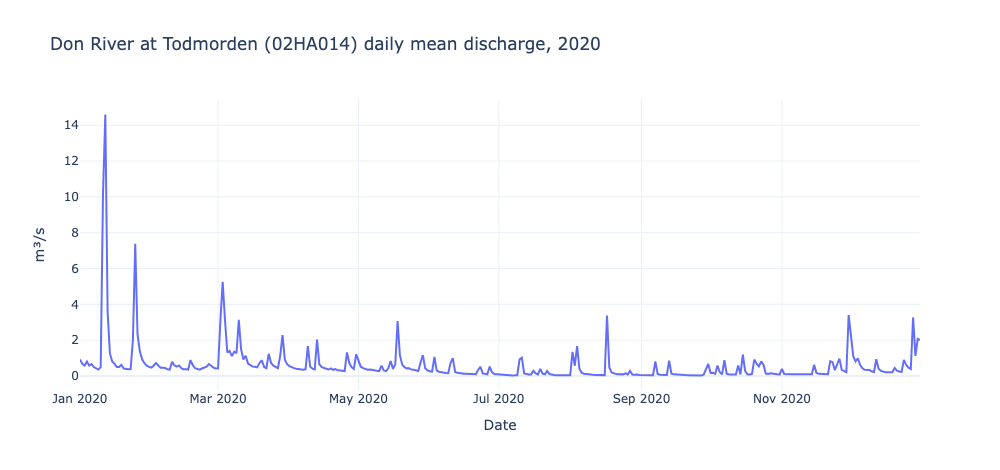

In [3]:
_, hydat = read("hydat")
flow = hydat[hydat.variable_id == "eccc:daily_mean_discharge"]
fig = go.Figure(go.Scatter(x=flow.time, y=flow.value, mode="lines", connectgaps=False))
fig.update_layout(title="Don River at Todmorden (02HA014) daily mean discharge, 2020",
                  xaxis_title="Date", yaxis_title="m³/s")
fig.show()

## USGS daily mean streamflow

USGS discharge keeps its source unit (ft³/s), and USGS may revise recent values.
The pipeline selects gauges with a small box; with `--station` it selects one
monitoring location by ID.

usgs: 731 rows, 0 without a value; 5 checksummed resources; terms: USGS public-domain data


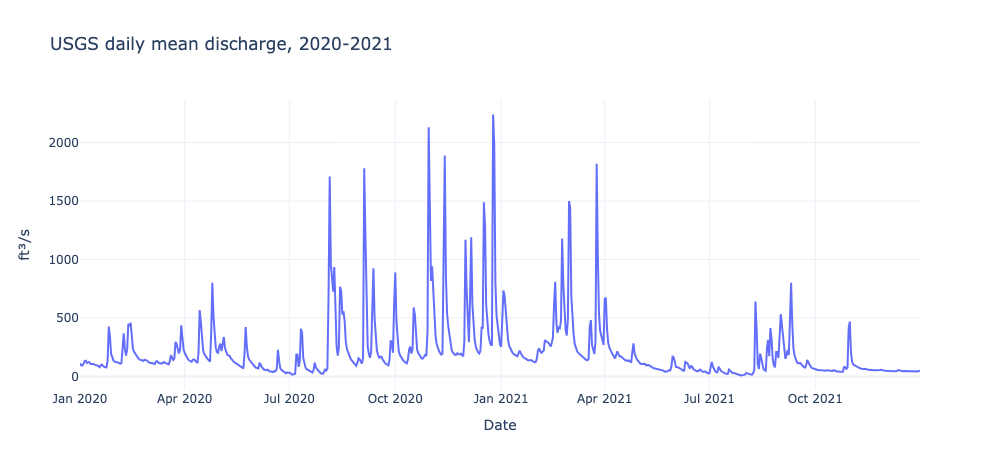

In [4]:
_, usgs = read("usgs")
fig = go.Figure([
    go.Scatter(x=group.time, y=group.value, mode="lines", name=station)
    for station, group in usgs.sort_values("time").groupby("station_id")
])
fig.update_layout(title="USGS daily mean discharge, 2020-2021", xaxis_title="Date", yaxis_title="ft³/s")
fig.show()

## CHIRPS v3 monthly precipitation

Monthly totals on CHIRPS pixels; only the pixels inside the box are read from
each monthly file. Each pixel keeps its footprint (`support_id`, `geometry`).

chirps: 108 rows, 0 without a value; 12 checksummed resources; terms: CC-BY-4.0


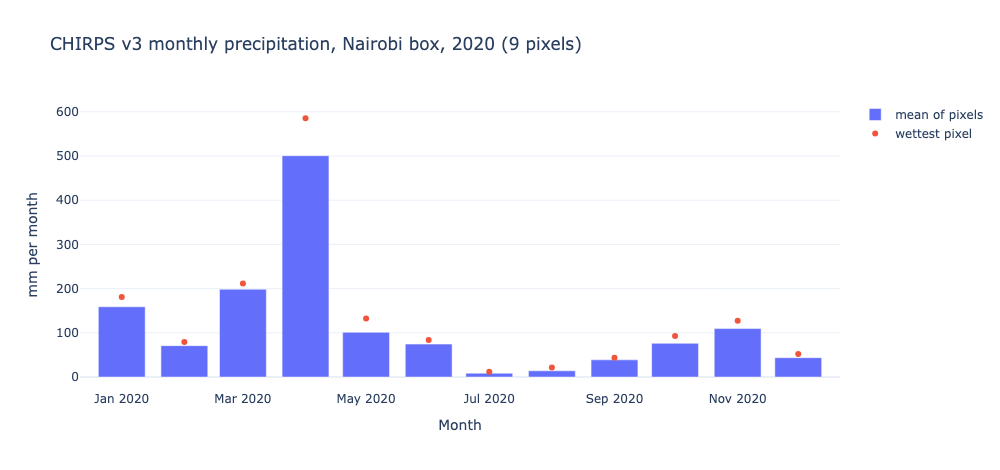

In [5]:
_, chirps = read("chirps")
monthly = chirps.groupby("time").value.agg(["mean", "min", "max"]).reset_index()
fig = go.Figure([
    go.Bar(x=monthly.time, y=monthly["mean"], name="mean of pixels"),
    go.Scatter(x=monthly.time, y=monthly["max"], mode="markers", name="wettest pixel"),
])
fig.update_layout(title=f"CHIRPS v3 monthly precipitation, Nairobi box, 2020 ({chirps.support_id.nunique()} pixels)",
                  xaxis_title="Month", yaxis_title="mm per month")
fig.show()

## IBTrACS storm tracks

Track points of every storm that passed through the box in 2024, as reported by
the USA agency. `group_id` is the storm ID; the box clips each track to its
positions inside it. Storm tracks are not an asset wind hazard.

ibtracs: 496 rows, 0 without a value; 1 checksummed resources; terms: NOAA open-use terms; originator terms may apply
Points per storm in the box: {'2024279N21265': 53, '2024309N13283': 41, '2024181N09320': 40, '2024253N21266': 30, '2024268N17278': 29, '2024216N20284': 28, '2024170N20267': 22, '2024183N20265': 5}


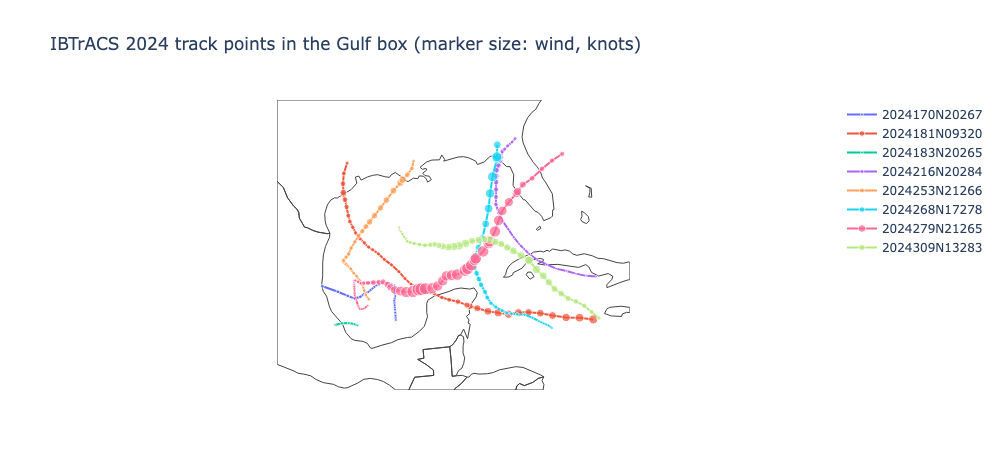

In [6]:
summary, tracks = read("ibtracs")
print("Points per storm in the box:", summary["storms"])
wind = tracks[tracks.variable_id == "ibtracs:USA:maximum_sustained_wind"].copy()
points = wind.geometry.map(shapely.from_wkb)
wind["longitude"], wind["latitude"] = points.map(lambda p: p.x), points.map(lambda p: p.y)
fig = go.Figure([
    go.Scattergeo(lon=group.longitude, lat=group.latitude, mode="lines+markers", name=storm,
                  marker=dict(size=group.value.fillna(0) / 12))
    for storm, group in wind.sort_values("time").groupby("group_id")
])
fig.update_layout(title="IBTrACS 2024 track points in the Gulf box (marker size: wind, knots)",
                  geo=dict(scope="north america", lonaxis_range=[-100, -76], lataxis_range=[16, 33]))
fig.show()

## NOAA extreme water levels

NOAA CO-OPS publishes detrended annual high-water values and the exceedance
levels fitted to them, with 90% confidence intervals. The pipeline writes the
annual series, the published central exceedance curve (`levels.parquet`) and its
intervals (`confidence_intervals.parquet`). Levels use the station datum and
epoch; they are not asset flood depths or projections.

noaa-water-levels: 98 rows, 0 without a value; 2 checksummed resources; terms: NOAA open-use terms; originator terms may apply


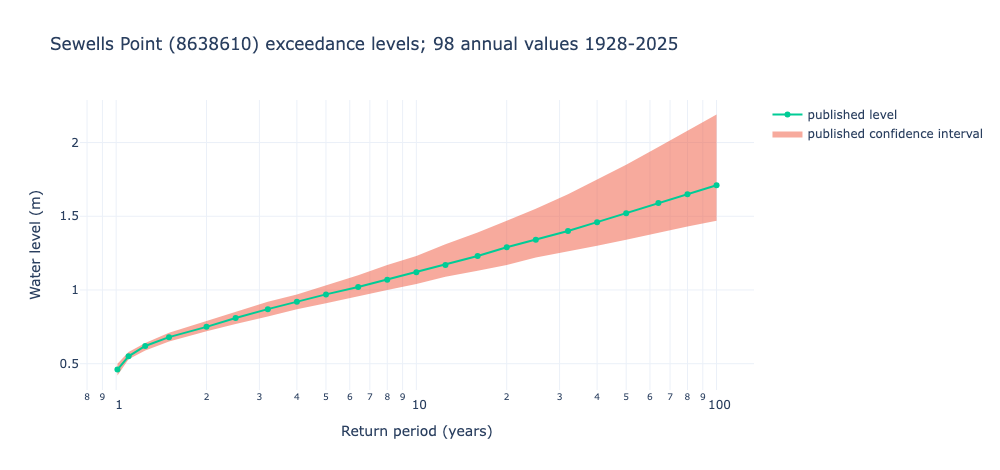

In [7]:
summary, annual = read("noaa-water-levels")
intervals = pq.read_table(summary["outputs"]["confidence_intervals"]).to_pandas()
intervals["years"] = intervals.coordinate.map(lambda c: c["years"])
intervals = intervals.sort_values("years")
fig = go.Figure([
    go.Scatter(x=intervals.years, y=intervals.interval.map(lambda i: i["upper"]), mode="lines",
               line=dict(width=0), showlegend=False),
    go.Scatter(x=intervals.years, y=intervals.interval.map(lambda i: i["lower"]), mode="lines",
               line=dict(width=0), fill="tonexty", name="published confidence interval"),
    go.Scatter(x=intervals.years, y=intervals.value, mode="lines+markers", name="published level"),
])
fig.update_layout(title=f"Sewells Point (8638610) exceedance levels; {len(annual)} annual values "
                        f"{annual.time.min()}-{annual.time.max()}",
                  xaxis=dict(title="Return period (years)", type="log"), yaxis_title="Water level (m)")
fig.show()

## NOAA 2022 relative sea-level scenarios

Projections of relative sea-level change at the station for each 2022 Technical
Report scenario, with the published likely range. These are changes in mean
sea level, not water depths at assets.

noaa-sea-level: 225 rows, 0 without a value; 2 checksummed resources; terms: NOAA open-use terms; originator terms may apply


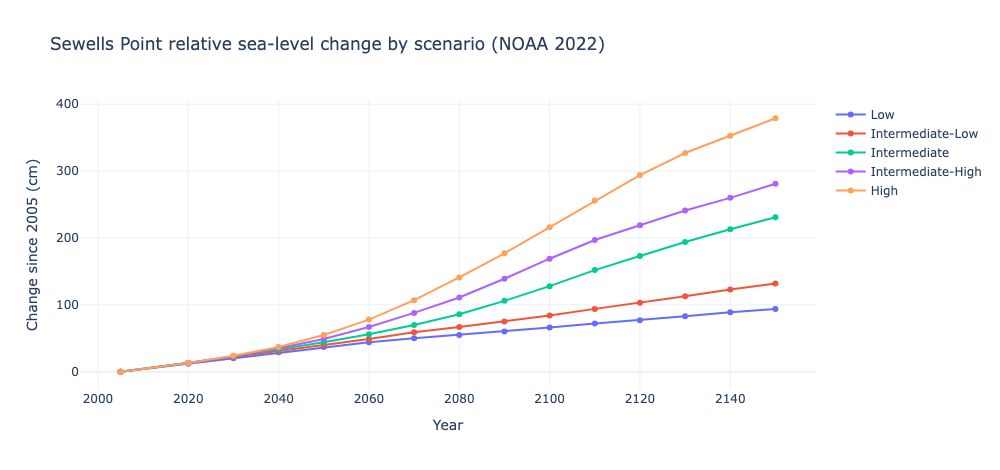

In [8]:
summary, slr = read("noaa-sea-level", name="projections")
unit = Projections.open(summary["outputs"]["projections"]).metadata.spec.variables[0].measurement.unit
central = slr[slr.variable_id == "noaa:relative_sea_level_change"].copy()
central["year"] = central.coordinate.map(lambda c: int(c["time"]))
fig = go.Figure([
    go.Scatter(x=group.year, y=group.value, mode="lines+markers", name=scenario)
    for scenario, group in central.sort_values("year").groupby("scenario_id", sort=False)
])
fig.update_layout(title="Sewells Point relative sea-level change by scenario (NOAA 2022)",
                  xaxis_title="Year", yaxis_title=f"Change since 2005 ({getattr(unit, 'value', unit)})")
fig.show()

## NEX-GDDP-CMIP6 annual maximum daily precipitation

NASA's downscaled CMIP6 data, read as annual samples: the wettest day of 2014 in
each 0.25° cell of a Toronto box, from one model's historical run. One model run
is not a projection range. Samples like these feed an explicit fit; see the
[CMIP6 notebook](cmip6_rx1day_projection.ipynb).

nex: 9 rows, 0 without a value; 4 checksummed resources; terms: 


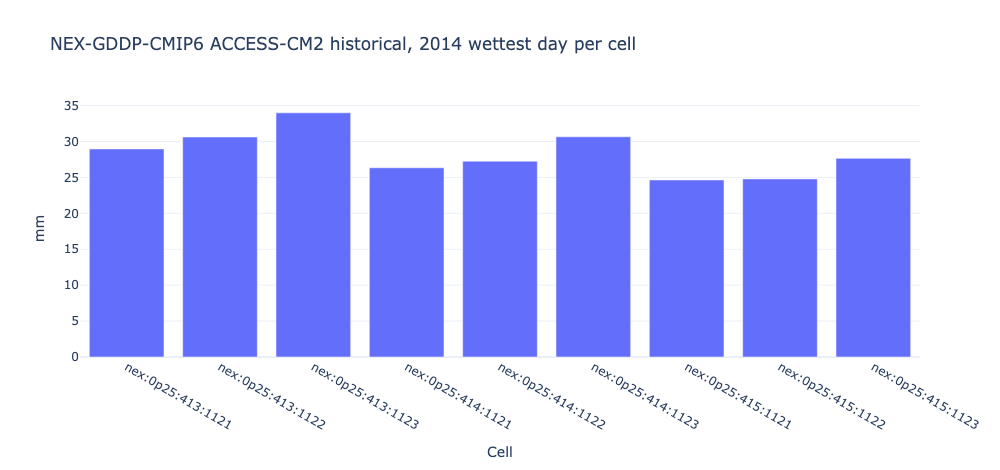

,support_id,time,value
0,nex:0p25:413:1121,2014,28.967334
1,nex:0p25:413:1122,2014,30.621180
2,nex:0p25:413:1123,2014,33.989928
3,nex:0p25:414:1121,2014,26.343161
4,nex:0p25:414:1122,2014,27.259604
5,nex:0p25:414:1123,2014,30.658891
6,nex:0p25:415:1121,2014,24.648891
7,nex:0p25:415:1122,2014,24.794728
8,nex:0p25:415:1123,2014,27.655048


In [9]:
_, nex = read("nex", name="samples")
fig = go.Figure(go.Bar(x=nex.support_id, y=nex.value))
fig.update_layout(title="NEX-GDDP-CMIP6 ACCESS-CM2 historical, 2014 wettest day per cell",
                  xaxis_title="Cell", yaxis_title="mm")
fig.show()
nex[["support_id", "time", "value"]]

## Reuse and reproduce

- Change the selection with `Options(station=..., bounds=(west, south, east, north),
  start=..., end=...)`, or the matching `--station/--bounds/--start/--end` flags.
- `cache_mode="offline"` (`--cache-mode offline`) replays the verified bytes in
  the cache without network access.
- Each `summary.json` lists the downloaded resources with their checksums,
  licences and attribution; keep it with any results you share.